# 1. Setup

In [ ]:
import pandas as pd
import numpy as np

from google.colab import drive
drive.mount('/content/drive')

folder = '/content/drive/MyDrive/ML_Regression_House_Prediction/'

train = pd.read_csv(folder + 'train.csv')
test = pd.read_csv(folder + 'test.csv')

Mounted at /content/drive


In [ ]:
# Check the shape

print('Train shape:', train.shape)
print('Test shape:', test.shape)

Train shape: (1460, 81)
Test shape: (1459, 80)


In [ ]:
# Look at the first rows

train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
# Check data types

train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [ ]:
# Summary statistics

train.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [ ]:
# Check duplicates

print('Duplicate rows in train:', train.duplicated().sum())
print('Duplicate Ids in train:', train['Id'].duplicated().sum())

Duplicate rows in train: 0
Duplicate Ids in train: 0


In [ ]:
# Check missing values

missing = train.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print(missing)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


In [ ]:
missing_test = test.isna().sum()
missing_test = missing_test[missing_test > 0].sort_values(ascending=False)

print(missing_test)

PoolQC          1456
MiscFeature     1408
Alley           1352
Fence           1169
MasVnrType       894
FireplaceQu      730
LotFrontage      227
GarageQual        78
GarageCond        78
GarageYrBlt       78
GarageFinish      78
GarageType        76
BsmtCond          45
BsmtQual          44
BsmtExposure      44
BsmtFinType1      42
BsmtFinType2      42
MasVnrArea        15
MSZoning           4
Functional         2
BsmtFullBath       2
Utilities          2
BsmtHalfBath       2
Exterior1st        1
Exterior2nd        1
TotalBsmtSF        1
BsmtUnfSF          1
BsmtFinSF2         1
BsmtFinSF1         1
KitchenQual        1
GarageArea         1
GarageCars         1
SaleType           1
dtype: int64


In [ ]:
# Check the target

train['SalePrice'].describe()

,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


## Markdown

**Outputs**

1. Shapes are correct. `train` has 81 columns and `test` has 80. The extra column is `SalePrice`.
2. There are no duplicate rows or IDs.
3. `SalePrice` ranges from 34,900 to 755,000. The mean (about 180,921) is above the median (163,000). This means the prices are skewed to the right. We fix this with a log transformation in Step 3.
4. Most missing values mean the house has no such feature. For example, 81 houses have no garage, so all `Garage` columns show 81 missing values.
5. `MasVnrType` shows 872 missing values. The data description lists “None” as a real value, and pandas reads the text “None” as empty. So most of these are not true gaps.
6. True gaps exist in `LotFrontage`, `Electrical`, and a few `test` columns, such as `MSZoning` and `KitchenQual`.



# 2. Data Cleaning

In [ ]:
# Make copies of the original data

train_clean = train.copy()
test_clean = test.copy()

In [ ]:
# Fix the data type of MSSubClass

# MSSubClass is a building type code, not a quantity
# Convert it to text so it is treated as a category
train_clean['MSSubClass'] = train_clean['MSSubClass'].astype(str)
test_clean['MSSubClass'] = test_clean['MSSubClass'].astype(str)

In [ ]:
# Fill “no feature” text columns with “None”

# Missing here means the house has no pool, alley, garage, basement, etc.
none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType',
             'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual',
             'GarageCond', 'BsmtQual', 'BsmtCond', 'BsmtExposure',
             'BsmtFinType1', 'BsmtFinType2']

for col in none_cols:
    train_clean[col] = train_clean[col].fillna('None')
    test_clean[col] = test_clean[col].fillna('None')

In [ ]:
# Fill “no feature” number columns with 0

# Missing here means no basement, no garage, or no masonry veneer
zero_cols = ['MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF',
             'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath',
             'GarageCars', 'GarageArea']

for col in zero_cols:
    train_clean[col] = train_clean[col].fillna(0)
    test_clean[col] = test_clean[col].fillna(0)

In [ ]:
# Fill GarageYrBlt

# Houses with no garage have no garage year
# Use the year the house was built as a neutral value
train_clean['GarageYrBlt'] = train_clean['GarageYrBlt'].fillna(train_clean['YearBuilt'])
test_clean['GarageYrBlt'] = test_clean['GarageYrBlt'].fillna(test_clean['YearBuilt'])

In [ ]:
# Fill the remaining gaps

# Remaining gaps are true missing values
# Text columns: use the most common value from train
# Number columns: use the median from train
for col in test_clean.columns:
    if train_clean[col].dtype == 'object':
        fill_value = train_clean[col].mode()[0]
    else:
        fill_value = train_clean[col].median()

    train_clean[col] = train_clean[col].fillna(fill_value)
    test_clean[col] = test_clean[col].fillna(fill_value)

In [ ]:
# Confirm no missing values remain

# Check that both files are now complete
print('Missing in train:', train_clean.isna().sum().sum())
print('Missing in test:', test_clean.isna().sum().sum())

Missing in train: 0
Missing in test: 0


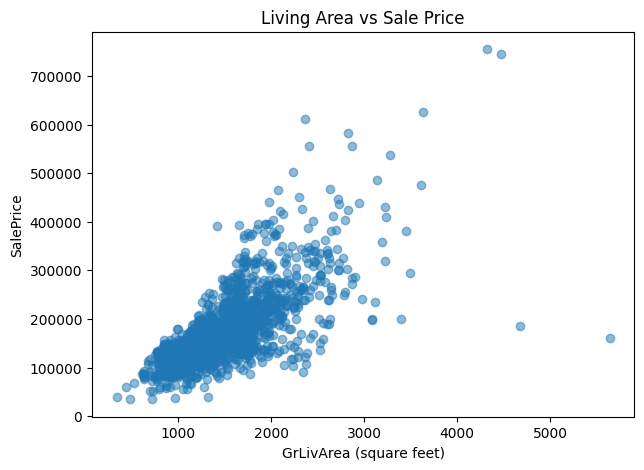

In [ ]:
# Look for outliers

# Outlier check: large living area with a low price
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.scatter(train_clean['GrLivArea'], train_clean['SalePrice'], alpha=0.5)
plt.xlabel('GrLivArea (square feet)')
plt.ylabel('SalePrice')
plt.title('Living Area vs Sale Price')
plt.show()

In [ ]:
# List the suspicious houses
train_clean[(train_clean['GrLivArea'] > 4000) & (train_clean['SalePrice'] < 300000)][['Id', 'GrLivArea', 'SalePrice']]

,Id,GrLivArea,SalePrice
523,524,4676,184750
1298,1299,5642,160000


In [ ]:
# Remove the outliers

# Remove the houses listed above from train only
# Never remove rows from test, because Kaggle needs every Id
train_clean = train_clean[~((train_clean['GrLivArea'] > 4000) & (train_clean['SalePrice'] < 300000))]

print('Train shape after removing outliers:', train_clean.shape)

Train shape after removing outliers: (1458, 81)


# 3. EDA

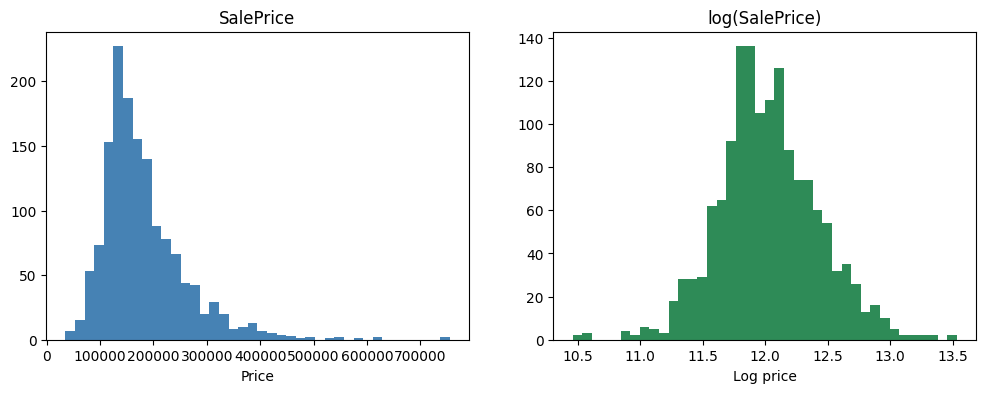

In [ ]:
# Distribution of SalePrice

import matplotlib.pyplot as plt
import seaborn as sns

# Compare SalePrice with log(SalePrice)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left plot: original price
axes[0].hist(train_clean['SalePrice'], bins=40, color='steelblue')
axes[0].set_title('SalePrice')
axes[0].set_xlabel('Price')

# Right plot: log of price
axes[1].hist(np.log(train_clean['SalePrice']), bins=40, color='seagreen')
axes[1].set_title('log(SalePrice)')
axes[1].set_xlabel('Log price')

plt.show()

In [ ]:
# Measure skewness (0 means symmetric)
print('Skew of SalePrice:', train_clean['SalePrice'].skew())
print('Skew of log(SalePrice):', np.log(train_clean['SalePrice']).skew())

Skew of SalePrice: 1.8812964895244009
Skew of log(SalePrice): 0.12156821443518166


In [ ]:
# Correlation of numeric features with SalePrice

numeric_cols = train_clean.select_dtypes(include='number')
correlations = numeric_cols.corr()['SalePrice'].sort_values(ascending=False)

print(correlations.head(11))

SalePrice       1.000000
OverallQual     0.795774
GrLivArea       0.734968
TotalBsmtSF     0.651153
GarageCars      0.641047
1stFlrSF        0.631530
GarageArea      0.629217
FullBath        0.562165
TotRmsAbvGrd    0.537769
YearBuilt       0.523608
GarageYrBlt     0.508719
Name: SalePrice, dtype: float64


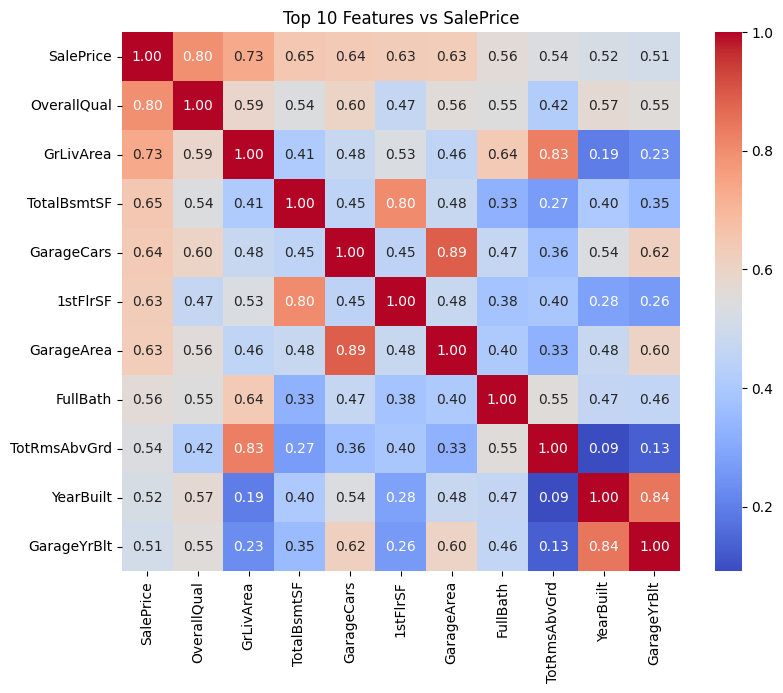

In [ ]:
# Heatmap of the top features

# Heatmap of the 10 features most correlated with SalePrice
top_features = correlations.head(11).index
top_corr = train_clean[top_features].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(top_corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Top 10 Features vs SalePrice')
plt.show()

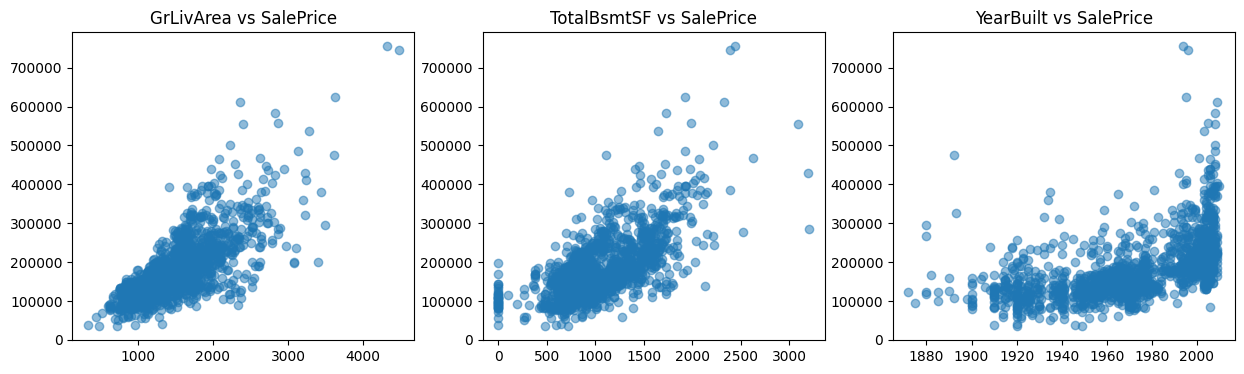

In [ ]:
# Scatter plots for key features

# Scatter plots of key features against SalePrice
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(train_clean['GrLivArea'], train_clean['SalePrice'], alpha=0.5)
axes[0].set_title('GrLivArea vs SalePrice')

axes[1].scatter(train_clean['TotalBsmtSF'], train_clean['SalePrice'], alpha=0.5)
axes[1].set_title('TotalBsmtSF vs SalePrice')

axes[2].scatter(train_clean['YearBuilt'], train_clean['SalePrice'], alpha=0.5)
axes[2].set_title('YearBuilt vs SalePrice')

plt.show()

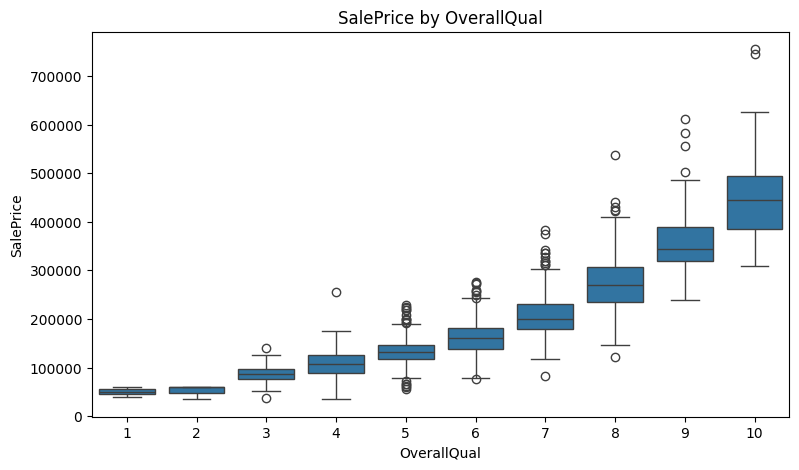

In [ ]:
# Box plot of price by OverallQual

# Step 3.6: SalePrice across overall quality levels
plt.figure(figsize=(9, 5))
sns.boxplot(x='OverallQual', y='SalePrice', data=train_clean)
plt.title('SalePrice by OverallQual')
plt.show()

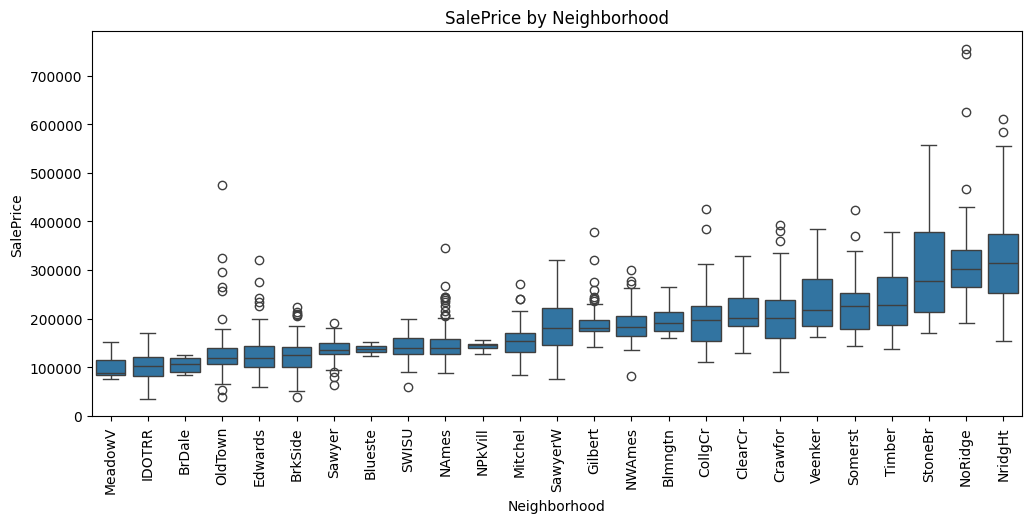

In [ ]:
# Box plot of price by Neighborhood

# SalePrice across neighborhoods, sorted by median price
order = train_clean.groupby('Neighborhood')['SalePrice'].median().sort_values().index

plt.figure(figsize=(12, 5))
sns.boxplot(x='Neighborhood', y='SalePrice', data=train_clean, order=order)
plt.xticks(rotation=90)
plt.title('SalePrice by Neighborhood')
plt.show()

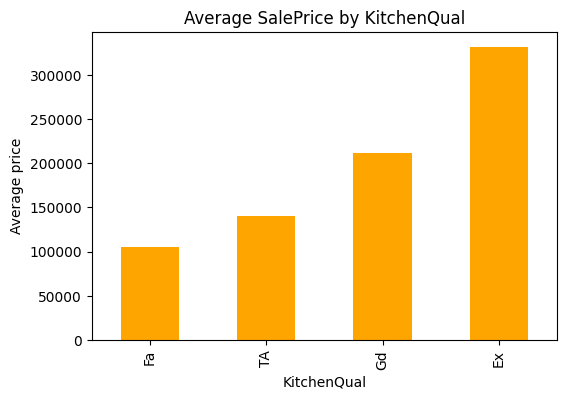

In [ ]:
# Average price by category (bar chart)

# Average price by kitchen quality
kitchen_mean = train_clean.groupby('KitchenQual')['SalePrice'].mean().sort_values()

plt.figure(figsize=(6, 4))
kitchen_mean.plot(kind='bar', color='orange')
plt.title('Average SalePrice by KitchenQual')
plt.ylabel('Average price')
plt.show()

## Markdown

EDA shows how the target behaves and which features relate to it

### What to look for

1. Skew: The log transformation should bring the skewness closer to 0.
2. Top correlations: Expect `OverallQual` and `GrLivArea` to have the strongest correlations with `SalePrice`.
3. Scatter plots: Check whether the relationship between each feature and `SalePrice` follows an approximately straight line.
4. Box plots: Check whether prices increase with overall quality and differ across neighborhoods.
5. Insights: The final review needs at least two data-backed insights. Record two findings from these plots.

### **Outputs:**

### Distribution of SalePrice

1. The skew of `SalePrice` is 1.88. This is strongly right-skewed. The left histogram shows the same: a long tail of expensive houses.
2. The skew of `log(SalePrice)` is 0.12. This is close to 0, and the right histogram looks like a bell shape.
3. Decision: model `log(SalePrice)`. This also matches the brief’s metric.

### Correlations

1. `OverallQual` has the strongest link to price (0.80).
2. `GrLivArea` is second (0.73).
3. `TotalBsmtSF`, `GarageCars`, `1stFlrSF`, and `GarageArea` are all near 0.63 to 0.65.
4. Some features overlap with each other:
   - `GarageCars` and `GarageArea` (0.89)
   - `GrLivArea` and `TotRmsAbvGrd` (0.83)
   - `TotalBsmtSF` and `1stFlrSF` (0.80)
   - `YearBuilt` and `GarageYrBlt` (0.84)

Why overlap matters: two features that carry the same information can make Linear Regression coefficients unstable. This is one reason we try Ridge in Step 7. We keep all features for now.

### Scatter plots

1. `GrLivArea` and `TotalBsmtSF` show a clear upward, roughly straight-line trend. The spread widens as size grows.
2. `YearBuilt` shows a weaker link. Prices stay flat for older houses, then rise for houses built after about 1980.
3. About 37 houses have `TotalBsmtSF` of 0. These are houses with no basement. They sit on the left edge of the plot.

### Box plots

1. Median price rises at every step of `OverallQual`. The median for quality 10 is roughly 9 times higher than for quality 1 to 2.
2. Neighborhood matters. `NridgHt`, `NoRidge`, and `StoneBr` have the highest medians (about 280,000 to 315,000). `MeadowV`, `IDOTRR`, and `BrDale` have the lowest (about 90,000 to 105,000).
3. Some neighborhoods, such as `StoneBr` and `NoRidge`, have a wide spread. Neighborhood alone does not fix the price.

### Bar chart

Average price rises with kitchen quality: Fa (about 105,000), TA (about 140,000), Gd (about 210,000), Ex (about 330,000). Values are read from the chart, so they are approximate.

### **Insights**

1. Insight 1: `SalePrice` is right-skewed (skew 1.88). A log transform reduces it to 0.12, so we model `log(SalePrice)`.
2. Insight 2: `OverallQual` (0.80) and `GrLivArea` (0.73) have the strongest correlation with price. Higher quality and larger living area go with higher prices.
3. Insight 3: Neighborhood groups houses into clear price levels. Median prices differ by about three times between the lowest and highest neighborhoods.
4. Insight 4: Several features overlap, such as `GarageCars` and `GarageArea` (0.89). This can affect Linear Regression.

Correlation does not prove cause. A high quality score goes with a high price, but we cannot say it makes the price rise.


# 4. Feature Engineering

In [ ]:
# Create new features

# Create new features for both train and test
for df in [train_clean, test_clean]:

    # Total living area: basement + first floor + second floor
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']

    # Age of the house when sold
    df['HouseAge'] = df['YrSold'] - df['YearBuilt']

    # Total bathrooms: half baths count as 0.5
    df['TotalBath'] = (df['FullBath'] + 0.5 * df['HalfBath']
                       + df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath'])

In [ ]:
# Check the new features

print(train_clean[['TotalSF', 'HouseAge', 'TotalBath']].describe())

           TotalSF     HouseAge    TotalBath
count  1458.000000  1458.000000  1458.000000
mean   2557.150206    36.598080     2.207476
std     774.109803    30.240565     0.781341
min     334.000000     0.000000     1.000000
25%    2008.500000     8.000000     2.000000
50%    2473.000000    35.000000     2.000000
75%    3002.250000    54.000000     2.500000
max    6872.000000   136.000000     6.000000


In [ ]:
# Check for impossible values (a negative age is a data error)
print('Negative HouseAge in train:', (train_clean['HouseAge'] < 0).sum())
print('Negative HouseAge in test:', (test_clean['HouseAge'] < 0).sum())

Negative HouseAge in train: 0
Negative HouseAge in test: 1


In [ ]:
# Find the house

#Check the YearBuilt and YrSold values. They should differ by a small number of years.
# Show the test house with a negative HouseAge
test_clean[test_clean['HouseAge'] < 0][['Id', 'YearBuilt', 'YearRemodAdd', 'YrSold', 'SaleType', 'HouseAge']]

,Id,YearBuilt,YearRemodAdd,YrSold,SaleType,HouseAge
1089,2550,2008,2009,2007,New,-1


In [ ]:
# Fix the value

# Replace negative ages with 0 (house treated as new when sold)
train_clean['HouseAge'] = train_clean['HouseAge'].clip(lower=0)
test_clean['HouseAge'] = test_clean['HouseAge'].clip(lower=0)

In [ ]:
# Verify

# Confirm no negative ages remain
print('Negative HouseAge in train:', (train_clean['HouseAge'] < 0).sum())
print('Negative HouseAge in test:', (test_clean['HouseAge'] < 0).sum())
print('Minimum HouseAge in test:', test_clean['HouseAge'].min())

Negative HouseAge in train: 0
Negative HouseAge in test: 0
Minimum HouseAge in test: 0


In [ ]:
# Check for impossible years in GarageYrBlt

# GarageYrBlt is also a year column, so check it for impossible years.
print('Max GarageYrBlt in train:', train_clean['GarageYrBlt'].max())
print('Max GarageYrBlt in test:', test_clean['GarageYrBlt'].max())

Max GarageYrBlt in train: 2010.0
Max GarageYrBlt in test: 2207.0


In [ ]:
# Find the house

# Show test houses with an impossible GarageYrBlt
test_clean[test_clean['GarageYrBlt'] > 2010][['Id', 'YearBuilt', 'GarageYrBlt', 'GarageType', 'YrSold']]

,Id,YearBuilt,GarageYrBlt,GarageType,YrSold
1132,2593,2006,2207.0,Attchd,2007


In [ ]:
# Fix the value

# Replace impossible garage years with the year the house was built
bad_rows = test_clean['GarageYrBlt'] > 2010
test_clean.loc[bad_rows, 'GarageYrBlt'] = test_clean.loc[bad_rows, 'YearBuilt']

In [ ]:
# Verify

# Confirm the maximum garage year is now valid
print('Max GarageYrBlt in test:', test_clean['GarageYrBlt'].max())

Max GarageYrBlt in test: 2010.0


In [ ]:
# Check how the new features relate to price

# Correlation of new features with SalePrice
new_corr = train_clean[['TotalSF', 'HouseAge', 'TotalBath', 'SalePrice']].corr()['SalePrice']
print(new_corr)

TotalSF      0.832877
HouseAge    -0.524067
TotalBath    0.635896
SalePrice    1.000000
Name: SalePrice, dtype: float64


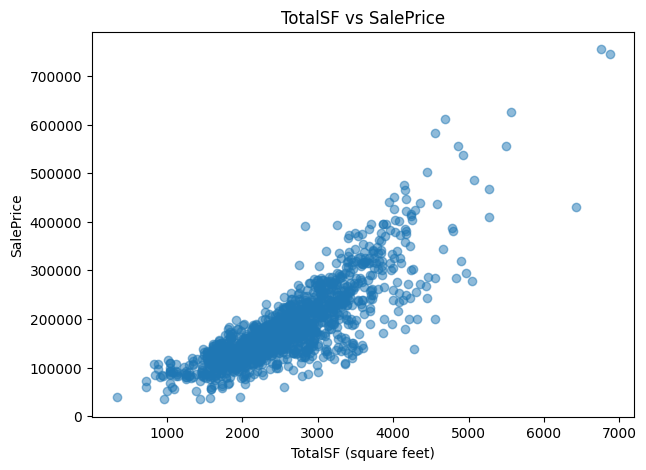

In [ ]:
# Scatter plot of TotalSF vs SalePrice
plt.figure(figsize=(7, 5))
plt.scatter(train_clean['TotalSF'], train_clean['SalePrice'], alpha=0.5)
plt.xlabel('TotalSF (square feet)')
plt.ylabel('SalePrice')
plt.title('TotalSF vs SalePrice')
plt.show()

## Markdown

### What to look for

1. `TotalSF` should have a higher correlation than `GrLivArea` (0.73). Check whether it does.
2. `HouseAge` should have a negative correlation. Older houses tend to cost less.
3. `TotalBath` should have a positive correlation.

### **Fix: One Negative HouseAge in Test**

### Cause

`HouseAge` is `YrSold` minus `YearBuilt`. A negative value means one test house has a sale year earlier than its build year. The data description says `New` sales can happen when a home is just constructed, so the dates may be off by a year. Train has 0 such rows, so the model has never seen a negative age.

### fix

Set the negative age to 0. Treat this house as new at the time of sale. Do not remove the row, because Kaggle needs every test Id.

### HouseAge fix worked

1. The house is Id 2550. It was built in 2008 and sold in 2007, with `SaleType` of `New`. So it was sold before completion, and the age was -1.
2. After `clip(lower=0)`, both negative counts are 0, and the minimum is 0.


### **Fix: `GarageYrBlt`**

1. The maximum `GarageYrBlt` in train is 2010. This is valid, since no house was sold after 2010.
2. The maximum in test is 2207. This is impossible. It is most likely a typing error, such as 2007
3. The model never saw a year like this in train, so it could predict a very wrong price for that house.

### fix

1. Only one house had a bad garage year: Id 1132, with `GarageYrBlt` of 2207. The number 2593 in the output is the row index, not a year.
2. This house was built in 2006 and sold in 2007, so the other years look normal.
3. After the fix, the maximum `GarageYrBlt` in test is 2010. This is valid.

### **Describe table**
1. TotalSF ranges from 334 to 6,872, with a mean of about 2,557. The smallest value corresponds to the house at the far left of the scatter plot.
2. HouseAge ranges from 0 to 136, with a mean of about 37. The minimum is now 0, confirming that the fix is in place.
3. TotalBath ranges from 1 to 6, with a median of 2. All these values are plausible.

### **New feature results**

| Feature     | Correlation with SalePrice |
| ----------- | -------------------------- |
| `TotalSF`   | 0.83                       |
| `HouseAge`  | -0.52                      |
| `TotalBath` | 0.64                       |

1. `TotalSF` (0.83) beats `GrLivArea` (0.73) and every other numeric feature. It is now the strongest size signal. It is even stronger than `OverallQual` (0.80).
2. `HouseAge` is negative, as expected. Older houses tend to sell for less. Its size (0.52) is close to `YearBuilt` (0.52), because both carry the same information.
3. `TotalBath` (0.64) is higher than `FullBath` alone (0.56). Combining the bath columns helped.
4. The `TotalSF` scatter plot shows a clear upward straight-line trend. The spread widens for larger houses.
5. One point near 6,400 sq ft sold for about 430,000. It sits well below the trend. I keep it for now, because removing more rows can hurt results on new data. We can check later if the residual plot flags it.

These results are correlations only. They do not prove that a feature causes the price to change.

### **Insight**

`TotalSF`, a feature we built, has a stronger link to price (0.83) than any original numeric feature. Combining basement, first floor, and second floor area gives a better size signal than any one of them alone.

# 5. Modelling

In [ ]:
# Set the target

# Use log(SalePrice) as the target
# The brief scores the log of price, so we model the log
y = np.log(train_clean['SalePrice'])

In [ ]:
# Separate features and remove Id

# Build the feature tables

# Id is only a label, so it is not a feature
# Keep the test Id for the Kaggle file
test_ids = test_clean['Id']

X = train_clean.drop(columns=['Id', 'SalePrice'])
X_test = test_clean.drop(columns=['Id'])

print('X shape:', X.shape)
print('X_test shape:', X_test.shape)

X shape: (1458, 82)
X_test shape: (1459, 82)


In [ ]:
# One-hot encode text columns

# Turn text columns into 0/1 columns
# drop_first=True removes one column per category to avoid duplicate information
X = pd.get_dummies(X, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, drop_first=True, dtype=int)

Why: a model cannot use text such as “Pave” or “Gravel”. One-hot encoding makes one 0/1 column for each category.

In [ ]:
# Match the test columns to the train columns

# Make test have the same columns, in the same order, as train

# Columns missing in test are filled with 0
# Columns that exist only in test are dropped
X_test = X_test.reindex(columns=X.columns, fill_value=0)

In [ ]:
# Check the result

# Check shapes and data types
print('X shape:', X.shape)
print('X_test shape:', X_test.shape)
print('Same columns:', list(X.columns) == list(X_test.columns))
print('Text columns left in X:', (X.dtypes == 'object').sum())
print('Missing values in X:', X.isna().sum().sum())
print('Missing values in X_test:', X_test.isna().sum().sum())
print('Target shape:', y.shape)

X shape: (1458, 274)
X_test shape: (1459, 274)
Same columns: True
Text columns left in X: 0
Missing values in X: 0
Missing values in X_test: 0
Target shape: (1458,)


## Markdown

Models need numbers only. We must separate the target, remove the Id, and turn text columns into numbers.

Encode train first and make test match the train columns. This keeps test information out of the process.

### **Outputs**

1. Before encoding, both tables have 82 columns, matching the expected count.
2. After encoding, both tables have 274 columns, and `Same columns` is `True`.
3. No text columns or missing values remain.
4. `X` has 1,458 rows, `X_test` has 1,459 rows, and `y` has 1,458 values.



# 6. Split the Data

In [ ]:
# Split into train and validation sets

from sklearn.model_selection import train_test_split

# Split train.csv into 80% training and 20% validation
# random_state makes the split the same every time you run it
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
# Check the split

print('X_train:', X_train.shape)
print('X_val:', X_val.shape)
print('y_train:', y_train.shape)
print('y_val:', y_val.shape)

X_train: (1166, 274)
X_val: (292, 274)
y_train: (1166,)
y_val: (292,)


In [ ]:
# Check that both parts have a similar target average
print('Mean log price in train part:', round(y_train.mean(), 4))
print('Mean log price in validation part:', round(y_val.mean(), 4))

Mean log price in train part: 12.0234
Mean log price in validation part: 12.0266


## Markdown

### What to look for

1. `X_train` should have 1,166 rows, and `X_val` should have 292 rows. Both should have 274 columns.
2. The two target averages should be close. If they differ significantly, the split may be uneven.

### **Outputs**

1. `X_train` has 1,166 rows and `X_val` has 292 rows. Together, they make 1,458 rows, matching the size of `X`.
2. Both datasets have 274 columns, so no features were lost.
3. The mean log price is 12.0234 for the training set and 12.0266 for the validation set. The difference is about 0.003, indicating a balanced split.

# 7. Build Models

In [ ]:
# Create a place to store predictions

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Make an empty dictionary to hold each model's validation predictions
val_predictions = {}

In [ ]:
# Baseline model

# Baseline - always predict the average log price of the training part
baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)

val_predictions['Baseline'] = baseline.predict(X_val)

Why: every real model must beat this score. If it does not, the model has learned nothing useful.

In [ ]:
# Linear Regression - the main model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

val_predictions['Linear Regression'] = linear_model.predict(X_val)

Why: it draws the best straight-line relationship between the features and log(SalePrice).

Watch for one risk. With 274 columns and 1,166 rows, this model can overfit. If its score in Step 8 looks far worse than the others, this is the likely cause.

In [ ]:
# Ridge Regression

# Ridge Regression - Linear Regression with a penalty on large coefficients
# Scaling is needed here because the penalty treats all columns equally
# The pipeline fits the scaler on the training part only
ridge_model = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas=[1, 10, 30, 100, 300, 1000])
)
ridge_model.fit(X_train, y_train)

val_predictions['Ridge'] = ridge_model.predict(X_val)

# Show which penalty strength was chosen
print('Chosen alpha:', ridge_model.named_steps['ridgecv'].alpha_)

Chosen alpha: 300


Why: alpha is the penalty strength. A larger alpha shrinks the coefficients more. This calms the model when many columns overlap. RidgeCV tries each alpha inside the training part only, so the validation part stays untouched.

In [ ]:
# Decision Tree

# Decision Tree - splits the data with yes/no questions
# max_depth limits how deep the tree grows, to reduce overfitting
tree_model = DecisionTreeRegressor(max_depth=6, random_state=42)
tree_model.fit(X_train, y_train)

val_predictions['Decision Tree'] = tree_model.predict(X_val)

In [ ]:
# Random Forest

# Random Forest - the average of many decision trees
forest_model = RandomForestRegressor(n_estimators=100, random_state=42)
forest_model.fit(X_train, y_train)

val_predictions['Random Forest'] = forest_model.predict(X_val)

Why: a single tree is unstable. Averaging many trees gives a steadier result. This is the only “advanced” model

In [ ]:
# Check that all models ran

# Confirm each model produced one prediction per validation house
for name, predictions in val_predictions.items():
    print(name, '->', len(predictions), 'predictions')

Baseline -> 292 predictions
Linear Regression -> 292 predictions
Ridge -> 292 predictions
Decision Tree -> 292 predictions
Random Forest -> 292 predictions


## Markdown

We train each one on the same training part. We start with a baseline, so we know what a “no skill” score looks like.

In this step we only train the models and save their predictions.

### **Insight**

All five models ran successfully.

1. Each model produced 292 predictions, one for each house in the validation set.
2. Ridge selected `alpha=300`, which is within the middle of the tested range (1 to 1,000). The selected value is not at either extreme, suggesting that a fairly strong regularization penalty was useful. This is consistent with the overlapping and highly correlated features identified in Feature Engineering

# Evaluate the Models

In [ ]:
# Score every model

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Score each model on the validation set (log scale)
results = []

for name, predictions in val_predictions.items():
    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    mae = mean_absolute_error(y_val, predictions)
    r2 = r2_score(y_val, predictions)
    results.append([name, rmse, mae, r2])

results_table = pd.DataFrame(results, columns=['Model', 'RMSE (log)', 'MAE (log)', 'R2'])
results_table = results_table.sort_values('RMSE (log)').reset_index(drop=True)

print(results_table.round(4))

               Model  RMSE (log)  MAE (log)      R2
0              Ridge      0.1367     0.0913  0.8891
1  Linear Regression      0.1411     0.0940  0.8819
2      Random Forest      0.1469     0.0986  0.8720
3      Decision Tree      0.1969     0.1366  0.7701
4           Baseline      0.4106     0.3246 -0.0001


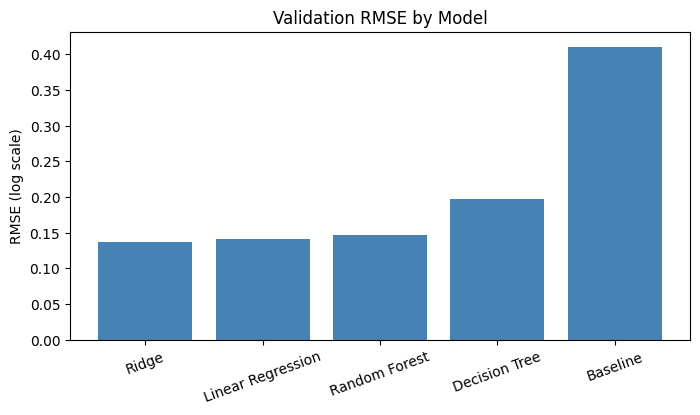

In [ ]:
# Compare RMSE in a bar chart

# Bar chart of validation RMSE (lower is better)
plt.figure(figsize=(8, 4))
plt.bar(results_table['Model'], results_table['RMSE (log)'], color='steelblue')
plt.ylabel('RMSE (log scale)')
plt.title('Validation RMSE by Model')
plt.xticks(rotation=20)
plt.show()

In [ ]:
# Pick the best model

# Name the model with the lowest RMSE
best_name = results_table.loc[0, 'Model']
print('Best model:', best_name)
print('Best RMSE (log):', round(results_table.loc[0, 'RMSE (log)'], 4))

Best model: Ridge
Best RMSE (log): 0.1367


## Markdown

We need one fair score for every model. The brief requires RMSE on the log scale. Since the target is already `log(SalePrice)`, calculating RMSE directly on `y_val` is correct.

### The metrics

1. RMSE: Measures the size of prediction errors, penalizing larger errors more heavily. On the log scale, an RMSE of 0.12 corresponds roughly to a 12% multiplicative error. Lower is better. This is the metric required by the brief.
2. MAE: Measures the average absolute prediction error on the log scale. Lower is better.
3. R²: Measures how much of the variation in log prices the model explains. A score of 1 is perfect, 0 means performance equivalent to predicting the target mean, and a negative score means the model performs worse than that baseline.

### **Outputs**

| Model             | RMSE (log) | MAE (log) | R²      |
| ----------------- | ---------- | --------- | ------- |
| Ridge             | 0.1367     | 0.0913    | 0.8891  |
| Linear Regression | 0.1411     | 0.0940    | 0.8819  |
| Random Forest     | 0.1469     | 0.0986    | 0.8720  |
| Decision Tree     | 0.1969     | 0.1366    | 0.7701  |
| Baseline          | 0.4106     | 0.3246    | -0.0001 |

### How to read it

1. The baseline R² is approximately 0, as expected. It predicts the target mean and provides a reference for comparison.
2. All four trained models outperform the baseline. Ridge reduces RMSE by about 67%, from 0.4106 to 0.1367.
3. Ridge performs best on this validation split, with the lowest RMSE of 0.1367.
4. Ridge explains about 89% of the variation in log price, with an R² of 0.8891.
5. The Decision Tree is the weakest trained model, with an RMSE of 0.1969.

### A correction to the earlier warning

Linear Regression did not perform substantially worse despite having 274 columns. Its RMSE of 0.1411 is close to Ridge's 0.1367. Ridge provides a modest improvement, but the results alone do not establish how much overfitting occurs.

### Caution

1. The top three models have relatively close RMSE scores: 0.1367, 0.1411, and 0.1469.
2. The models were evaluated on one validation set of 292 houses. Their rankings may change with a different split.
3. Ridge scored lowest on this validation set, but it has not been proven substantially better than the other top models.
4. “Ridge scored lowest on the validation set” rather than “Ridge is clearly the best.”

# Actual vs Predicted

In [ ]:
# Get the Ridge predictions and residuals

# Take the best model's validation predictions
best_predictions = val_predictions[best_name]

# Residual = actual - predicted (log scale)
residuals = y_val - best_predictions

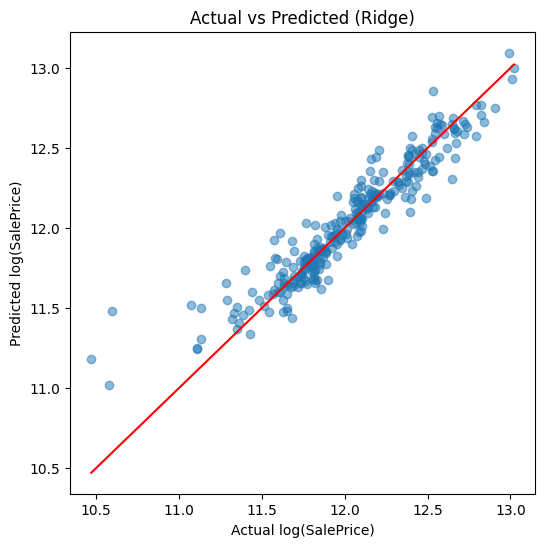

In [ ]:
# Actual vs predicted plot

# Scatter plot of actual vs predicted log price
plt.figure(figsize=(6, 6))
plt.scatter(y_val, best_predictions, alpha=0.5)

# Reference line: points on this line are perfect predictions
line_min = y_val.min()
line_max = y_val.max()
plt.plot([line_min, line_max], [line_min, line_max], color='red')

plt.xlabel('Actual log(SalePrice)')
plt.ylabel('Predicted log(SalePrice)')
plt.title('Actual vs Predicted (Ridge)')
plt.show()

Points close to the red line are good predictions. Points far above the line are overestimates. Points far below are underestimates.

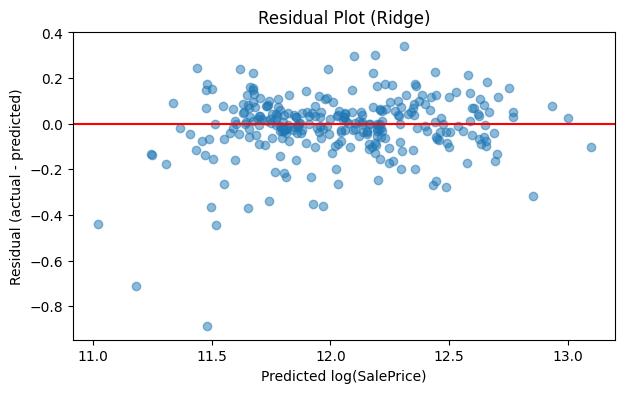

In [ ]:
# Residual plot

# Residuals against predicted values
plt.figure(figsize=(7, 4))
plt.scatter(best_predictions, residuals, alpha=0.5)
plt.axhline(0, color='red')

plt.xlabel('Predicted log(SalePrice)')
plt.ylabel('Residual (actual - predicted)')
plt.title('Residual Plot (Ridge)')
plt.show()

A good plot looks like a random cloud around 0. A curve or a funnel shape means the model misses a pattern.

In [ ]:
# Over or under estimation

# Count how often the model guesses too high or too low
print('Average residual:', round(residuals.mean(), 4))
print('Overestimated (residual below 0):', (residuals < 0).sum())
print('Underestimated (residual above 0):', (residuals > 0).sum())

Average residual: -0.0118
Overestimated (residual below 0): 148
Underestimated (residual above 0): 144


An average residual near 0 means no strong lean in one direction.

In [ ]:
# Largest errors

# Show the 5 houses with the largest errors
errors = pd.DataFrame({
    'Id': train_clean.loc[X_val.index, 'Id'],
    'Actual price': np.exp(y_val),
    'Predicted price': np.exp(best_predictions),
    'Residual (log)': residuals
})
errors['Abs error'] = errors['Residual (log)'].abs()

errors.sort_values('Abs error', ascending=False).head(5).round(3)

,Id,Actual price,Predicted price,Residual (log),Abs error
30,31,40000.0,96926.780,-0.885,0.885
916,917,35311.0,71846.844,-0.710,0.710
1432,1433,64500.0,100459.519,-0.443,0.443
533,534,39300.0,61067.542,-0.441,0.441
589,590,79500.0,115256.009,-0.371,0.371


In [ ]:
# Error in dollars

# RMSE in dollars, for context
# The brief's metric is the log RMSE from Step 8, not this number
dollar_rmse = np.sqrt(mean_squared_error(np.exp(y_val), np.exp(best_predictions)))
print('Validation RMSE in dollars:', round(dollar_rmse, 2))

Validation RMSE in dollars: 22679.86


In [ ]:
# Look at traits of the 5 largest errors
big_errors = [31, 917, 1433, 534, 590]
train_clean[train_clean['Id'].isin(big_errors)][['Id', 'MSZoning', 'Neighborhood', 'OverallQual', 'OverallCond', 'SaleCondition', 'TotalSF']]

,Id,MSZoning,Neighborhood,OverallQual,OverallCond,SaleCondition,TotalSF
30,31,C (all),IDOTRR,4,4,Normal,1966
533,534,RL,BrkSide,1,3,Normal,334
589,590,RM,BrkSide,5,6,Normal,1521
916,917,C (all),IDOTRR,2,3,Abnorml,960
1432,1433,RL,OldTown,4,6,Normal,1624


In [ ]:
# Step 9.5c: Check how many houses are in each zoning group and their prices
train_clean.groupby('MSZoning')['SalePrice'].agg(['count', 'mean', 'median'])

,count,mean,median
MSZoning,,,
C (all),10,74528.000000,74700.0
FV,65,214014.061538,205950.0
RH,16,131558.375000,136500.0
RL,1149,191037.422977,174000.0
RM,218,126316.830275,120500.0


## Markdown

RMSE is a single number that can hide patterns in prediction errors. These plots show where Ridge performs well, where it makes errors, and whether it tends to overestimate or underestimate prices.

A residual is calculated as `actual - predicted` on the log scale.

1. A positive residual means the model underestimated the price.
2. A negative residual means the model overestimated the price.

### What to look for

1. In Actual vs predicted plot, do the points follow the red reference line? Pay particular attention to the lower and higher price ranges.
2. In Residual plot, do the residuals form a random cloud, or is there a curve or fan-shaped pattern?
3. In Over or under estimation, is the average residual close to 0?
4. In Largest errors, do the houses with the largest errors share any traits, such as unusual size, a new sale, or an abnormal sale condition?

### **Outputs**

The outputs are correct. Here is how to read them.

### Actual vs predicted

1. Most points sit close to the red line from about 11.5 to 13.0. Ridge works well for mid-priced and expensive houses.
2. At the low end (actual below 11.0), the points sit well below the line. Ridge predicts these cheap houses too high.
3. The three leftmost points are the clearest cases. Their actual log prices are about 10.5 to 10.6, and the predictions are about 11.0 to 11.5.

### Residual plot

1. The middle of the plot is a fairly even cloud around 0. There is no curve, so the straight-line model fits the main part of the data.
2. The spread is wider at the low predicted end (below about 11.7). Errors there are larger and lean negative.
3. The few large negative points (about -0.7 to -0.9) are the same low-priced houses seen in 9.2.

### Over or under estimation

1. The average residual is -0.0118. This is very close to 0, so there is no strong overall lean.
2. 148 houses were overestimated and 144 were underestimated. The split is almost even.
3. The small negative average comes from the few large overestimates at the low end.

### Largest errors

| Id   | Actual | Predicted | Residual (log) |
| ---- | ------ | --------- | -------------- |
| 31   | 40,000 | 96,927    | -0.885         |
| 917  | 35,311 | 71,847    | -0.710         |
| 1433 | 64,500 | 100,460   | -0.443         |
| 534  | 39,300 | 61,068    | -0.441         |
| 590  | 79,500 | 115,256   | -0.371         |

1. All five errors are overestimates. Each house sold for less than Ridge expected.
2. The top two are far off. Ridge predicted more than double the actual price for Id 31 and Id 917.
3. All five have low actual prices (35,000 to 80,000). These are the cheapest houses in the data.
4. I do not know why these houses sold so low. Possible causes are poor condition, an abnormal sale, or a feature the model does not capture. To find out, check `SaleCondition`, `OverallCond`, and `MSZoning` for these Ids. I will not guess.



# Validation

In [ ]:
# Refit Ridge on all training data

# Refit the best model on the full training data (X and y)
# More houses give the model more to learn from
final_model = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas=[1, 10, 30, 100, 300, 1000])
)
final_model.fit(X, y)

print('Chosen alpha:', final_model.named_steps['ridgecv'].alpha_)

Chosen alpha: 300


In [ ]:
# Predict on test.csv

# Predict log prices for the test houses
test_log_predictions = final_model.predict(X_test)

# Convert from log scale back to dollars
test_predictions = np.exp(test_log_predictions)

In [ ]:
# Check the predictions

# Step 10.3: Check the predictions before saving
print('Number of predictions:', len(test_predictions))
print('Min price:', round(test_predictions.min(), 2))
print('Max price:', round(test_predictions.max(), 2))
print('Mean price:', round(test_predictions.mean(), 2))
print('Any missing:', np.isnan(test_predictions).sum())
print('Any negative:', (test_predictions < 0).sum())

Number of predictions: 1459
Min price: 51608.8
Max price: 1509892.93
Mean price: 176760.5
Any missing: 0
Any negative: 0


In [ ]:
# Save the submission file

# Build the file in the format Kaggle needs: Id,SalePrice
submission = pd.DataFrame({
    'Id': test_ids,
    'SalePrice': test_predictions
})

submission.to_csv('submission.csv', index=False)
submission.head()

,Id,SalePrice
0,1461,116998.091831
1,1462,158725.363892
2,1463,180361.047384
3,1464,198664.088901
4,1465,192339.314910


In [ ]:
# Download the file to your computer
from google.colab import files
files.download('submission.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Find the extreme predictions

# List test houses with predicted price above the train maximum
check = test_clean.copy()
check['Predicted'] = test_predictions

check[check['Predicted'] > 755000][['Id', 'Neighborhood', 'OverallQual', 'TotalSF', 'GrLivArea', 'TotalBsmtSF', 'LotArea', 'Predicted']]

,Id,Neighborhood,OverallQual,TotalSF,GrLivArea,TotalBsmtSF,LotArea,Predicted
1089,2550,Edwards,10,10190.0,5095,5095.0,39290,1.509893e+06


In [ ]:
# Compare with the largest values in train
train_clean[['TotalSF', 'GrLivArea', 'TotalBsmtSF', 'LotArea']].max()

,0
TotalSF,6872
GrLivArea,4476
TotalBsmtSF,3206
LotArea,215245


In [ ]:
# Count how many predictions are above 600,000
print('Predictions above 600,000:', (test_predictions > 600000).sum())

Predictions above 600,000: 1


In [ ]:
# Check the house first

# Look at the size columns of this house
test_clean[test_clean['Id'] == 2550][['Id', '1stFlrSF', '2ndFlrSF', 'TotalBsmtSF', 'GrLivArea', 'YearBuilt', 'SaleType', 'SaleCondition']]

,Id,1stFlrSF,2ndFlrSF,TotalBsmtSF,GrLivArea,YearBuilt,SaleType,SaleCondition
1089,2550,5095,0,5095.0,5095,2008,New,Partial


In [ ]:
# Cap the prediction

# Cap predictions at the highest price seen in train
max_train_price = train_clean['SalePrice'].max()

test_predictions = np.minimum(test_predictions, max_train_price)

print('Max price after cap:', round(test_predictions.max(), 2))
print('Houses changed:', (np.exp(test_log_predictions) > max_train_price).sum())

Max price after cap: 755000.0
Houses changed: 1


In [ ]:
# Save the submission file

# Build the file in the format Kaggle needs: Id,SalePrice
submission = pd.DataFrame({
    'Id': test_ids,
    'SalePrice': test_predictions
})

submission.to_csv('submission.csv', index=False)

print('Rows:', len(submission))
print('Columns:', list(submission.columns))
print('Any missing:', submission['SalePrice'].isna().sum())
submission.head()

Rows: 1459
Columns: ['Id', 'SalePrice']
Any missing: 0


,Id,SalePrice
0,1461,116998.091831
1,1462,158725.363892
2,1463,180361.047384
3,1464,198664.088901
4,1465,192339.314910


In [ ]:
# Download the file to your computer
from google.colab import files
files.download('submission.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Summary

### Key findings

1. `SalePrice` is right-skewed (skewness 1.88). Applying a log transformation reduces the skewness to 0.12, so we modeled `log(SalePrice)`.
2. `OverallQual` (0.80) and `GrLivArea` (0.73) have the strongest correlations with price among the original features.
3. The engineered feature `TotalSF` has a correlation of 0.83, higher than any original numeric feature.
4. Median sale prices differ clearly by neighborhood.
5. Ridge scored lowest on the validation set, with an RMSE of 0.1367 (log), MAE of 0.0913, and R² of 0.8891. The baseline RMSE was 0.4106.
6. Ridge showed no strong overall bias, with an average residual of -0.0118.
7. The largest errors were overestimates of low-priced houses. Two of these houses were zoned `C (all)`, a category containing only 10 houses.

### Results table (validation, log scale)

| Model             | RMSE   | MAE    | R²      |
| ----------------- | ------ | ------ | ------- |
| Ridge             | 0.1367 | 0.0913 | 0.8891  |
| Linear Regression | 0.1411 | 0.0940 | 0.8819  |
| Random Forest     | 0.1469 | 0.0986 | 0.8720  |
| Decision Tree     | 0.1969 | 0.1366 | 0.7701  |
| Baseline          | 0.4106 | 0.3246 | -0.0001 |

Kaggle public score: 14,227.48.

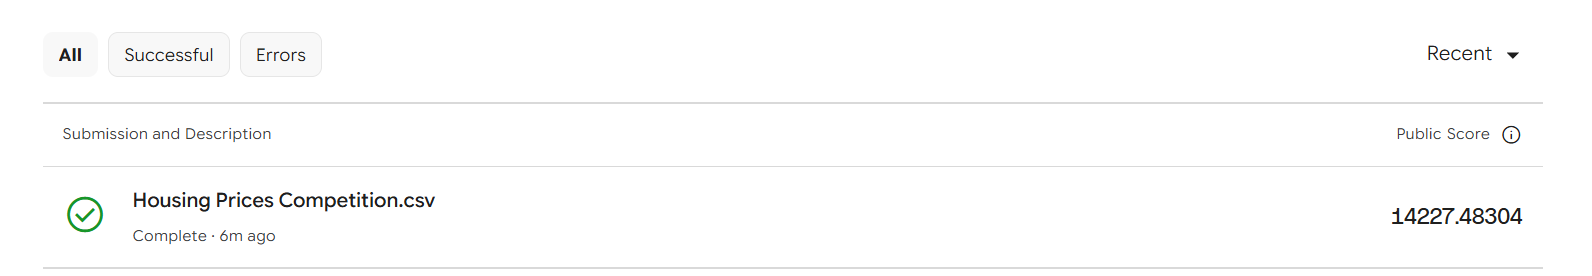

### Limitations

1. Model comparison used a single validation split of 292 houses. The top three models performed similarly.
2. Ridge overestimated very low-priced houses. Rare categories such as `C (all)` provide few training examples, which may contribute to these errors, although this has not been confirmed.
3. Two outlier houses were removed from the training data. One test house (Id 2550) had its `TotalSF` capped at 755,000. Its true sale price is unknown.
4. One impossible `GarageYrBlt` value (2207) and one negative `HouseAge` value in the test data were corrected using simple rules.
5. Correlation does not prove causation.

### Conclusion

Ridge Regression using `log(SalePrice)` and three engineered features achieved the lowest validation RMSE. It substantially outperformed the baseline. The Kaggle public score was 14,227.48, meeting the brief's target if lower scores are considered better.

### Recommendations

1. Group rare categories to improve estimates for underrepresented groups.
2. Use cross-validation for a more reliable comparison of model performance.
3. Try a more advanced model if the brief allows it.